# Does a smart (IoT) greenhouse change plant growth? An analysis of the Advanced IoT Agriculture dataset

**Author:** Abdulsobur Abiola Oladapo
**Tools:** Python, pandas, SciPy, scikit-posthocs, scikit-learn, seaborn 

**Link to Report**: https://drive.google.com/drive/folders/13_7jBBI2YH6huKBgjRPb87pkoH0fMuLv?usp=drive_link 

## Data source and attribution
- **Dataset:** *Advanced IoT Agriculture 2024* (`Advanced_IoT_Dataset.csv`), Kaggle, uploaded by `wisam1985` — <https://www.kaggle.com/datasets/wisam1985/advanced-iot-agriculture-2024>
- **Origin (per the dataset description):** master's thesis research by Mohammed Ismail Lifta (2023–2024), Department of Computer Science, College of Computer Science and Mathematics, **Tikrit University, Iraq**, supervised by Asst. Prof. Wisam Dawood Abdullah. Data were collected in an agriculture lab from plants grown in an **IoT greenhouse** and a **traditional greenhouse**.
- The dataset owner asks for proper attribution in any publication and asks that the data not be altered. This notebook therefore never overwrites the raw file; all cleaning happens on an in-memory copy.

## The question
> **Do plants from the two greenhouse types (S vs T) differ in growth, and which traits show it most clearly?**

Secondary questions:
1. Which traits separate the six classes (SA, SB, SC, TA, TB, TC) best?
2. Do the three `Random` replicates (R1–R3) behave like interchangeable samples?
3. Are the classification results trustworthy, or are they an artefact of how the data was generated or split?

## Key findings (numbers are produced by the cells below)
1. **The 30,000 rows are really 18 tight clusters.** Class × Replicate explains 99.6–100% of the variance in every trait; each of the 18 combinations holds ~1,670 near-copies of one pattern (section 4.3). Treating the rows as 30,000 independent plants would hugely overstate the evidence, so the greenhouse comparison is tested on the 18 group means (9 S vs 9 T).
2. **The two greenhouse types differ, and four differences hold up after correction.** T plants have ~15% *higher* chlorophyll (ACHP); S plants have ~29% more leaves (ANPL), ~26% longer roots (ARL) and ~40% larger leaf area (ALAP). Cohen's d is about 1.8–1.9 for each, and all four stay significant after Holm correction (adjusted p ≈ 0.01–0.03). Root weight (+66–69%), root diameter and root dry weight show large differences too, but with only 9 vs 9 groups they are not significant after correction. PDMRG and AWWGV show no meaningful difference.
3. **The A/B/C sub-groups act on different traits than the greenhouse does.** Greenhouse type explains most variance in ACHP, ANPL, ARL and ALAP (η² ≈ 0.47–0.50), while A/B/C explains most variance in plant height rate (PHR, η² ≈ 0.60), dry vegetative weight (ADWV) and root diameter (ARD).
4. **Classification is "too easy".** Logistic regression, random forest and gradient boosting all reach ≈100% accuracy under standard cross-validation, and even a *single* trait (ALAP, ARL or PDMRG) analysed with a depth-6 decision tree reaches ≈100%.
5. **That accuracy does not survive a harder test.** When a whole replicate is held out (train on two replicates, test on the third), six-class accuracy falls to roughly **33–67%** (random forest) and the single-trait trees drop to 0–50%. The simpler **S vs T** task stays at 100% for the random forest. 99–100% of the six-class errors stay within the same greenhouse.
6. **The data very likely contains simulated or augmented values** (sections 4.2–4.3), so conclusions describe this dataset and should not be read as field results.

> **Assumption to flag:** the dataset does not document its labels. I read **S = smart (IoT) greenhouse** and **T = traditional greenhouse** from the thesis context and the pattern in the data. The meaning of A/B/C is unknown. If the labels mean something else, the interpretation changes but the statistics do not.

## 1. Setup

In [1]:
import re, warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import scikit_posthocs as sp
from statsmodels.stats.multitest import multipletests

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import (LeaveOneGroupOut, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 42
DATA_PATH = next(p for p in [Path("../data/Advanced_IoT_Dataset.csv"),
                             Path("data/Advanced_IoT_Dataset.csv")] if p.exists())
FIG_DIR = Path("../figures") if DATA_PATH.parts[0] == ".." else Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Load the raw data and take a first look
The raw file is loaded as-is into `raw`; everything after this works on a copy.

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (30000, 14)


,Random,Average of chlorophyll in the plant (ACHP),Plant height rate (PHR),Average wet weight of the growth vegetative (AWWGV),Average leaf area of the plant (ALAP),Average number of plant leaves (ANPL),Average root diameter (ARD),Average dry weight of the root (ADWR),Percentage of dry matter for vegetative growth (PDMVG),Average root length (ARL),Average wet weight of the root (AWWR),Average dry weight of vegetative plants (ADWV),Percentage of dry matter for root growth (PDMRG),Class
0,R1,34.533468,54.566983,1.147449,1284.229549,4.999713,16.274918,1.706810,18.399982,19.739037,2.949240,0.209251,57.633906,SA
1,R1,34.489028,54.567692,1.149530,1284.247744,5.024259,16.269452,1.700930,18.398289,19.758836,2.943137,0.216154,57.633697,SA
2,R2,33.100405,67.067344,1.104647,1009.208996,5.007652,15.980760,1.185391,19.398789,20.840822,2.861635,0.200113,41.289875,SA
3,R1,34.498319,54.559049,1.137759,1284.227623,4.991501,16.276710,1.716396,18.413613,19.736098,2.946784,0.223092,57.645661,SA
4,R3,36.297008,45.588894,1.363205,981.470310,4.003682,16.979894,0.777428,31.423772,17.331894,2.766242,0.424172,27.898619,SA


In [3]:
print([repr(c) for c in raw.columns])

["'Random'", "' Average  of chlorophyll in the plant (ACHP)'", "' Plant height rate (PHR)'", "'Average wet weight of the growth vegetative (AWWGV)'", "'Average leaf area of the plant (ALAP)'", "'Average number of plant leaves (ANPL)'", "'Average root diameter (ARD)'", "' Average dry weight of the root (ADWR)'", "' Percentage of dry matter for vegetative growth (PDMVG)'", "'Average root length (ARL)'", "'Average wet weight of the root (AWWR)'", "' Average dry weight of vegetative plants (ADWV)'", "'Percentage of dry matter for root growth (PDMRG)'", "'Class'"]


Several column names carry **leading spaces** (e.g. `' Plant height rate (PHR)'`) and one has a **double space** (`'Average  of chlorophyll...'`). Left alone, these cause silent `KeyError`s later, so the first cleaning step is to tidy the names.

## 3. Cleaning and data dictionary
What changes (and nothing else):

| Change | Why |
|---|---|
| Strip and collapse whitespace in column names | Prevents hidden-space bugs |
| Rename the 12 trait columns to their abbreviations (ACHP, PHR, ...) | Short, unambiguous names for code and charts |
| Rename `Random` to `Replicate` | It behaves as a replicate/batch label, not an ID (section 7) |
| Split `Class` into `Greenhouse` (S/T) and `Group` (A/B/C) | Lets us test the greenhouse effect directly |

No rows are dropped and no values are altered.

In [4]:
df = raw.copy()
df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)

full_names = {c: re.search(r"\((\w+)\)", c).group(1) for c in df.columns if "(" in c}
abbr_to_full = {v: re.sub(r"\s*\(\w+\)", "", k) for k, v in full_names.items()}
df = df.rename(columns=full_names).rename(columns={"Random": "Replicate"})

df["Greenhouse"] = df["Class"].str[0]   # assumed: S = smart/IoT, T = traditional
df["Group"] = df["Class"].str[1]        # A / B / C (meaning undocumented)

TRAITS = list(full_names.values())
SHOOT = ["ACHP", "PHR", "AWWGV", "ALAP", "ANPL", "PDMVG", "ADWV"]
ROOT = ["ARD", "ADWR", "ARL", "AWWR", "PDMRG"]
assert set(SHOOT + ROOT) == set(TRAITS)
assert len(df) == len(raw)

dictionary = pd.DataFrame({
    "Abbreviation": TRAITS,
    "Meaning": [abbr_to_full[t] for t in TRAITS],
    "Type": ["Shoot" if t in SHOOT else "Root" for t in TRAITS],
})
dictionary

,Abbreviation,Meaning,Type
0,ACHP,Average of chlorophyll in the plant,Shoot
1,PHR,Plant height rate,Shoot
2,AWWGV,Average wet weight of the growth vegetative,Shoot
3,ALAP,Average leaf area of the plant,Shoot
4,ANPL,Average number of plant leaves,Shoot
5,ARD,Average root diameter,Root
6,ADWR,Average dry weight of the root,Root
7,PDMVG,Percentage of dry matter for vegetative growth,Shoot
8,ARL,Average root length,Root
9,AWWR,Average wet weight of the root,Root


**Units are not documented in the source**, so values are compared only *relatively* (between groups), never against external benchmarks.

## 4. Data quality checks

In [5]:
quality = pd.Series({
    "Rows": len(df),
    "Missing cells": int(df.isna().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Duplicate rows (ignoring Replicate)": int(df.drop(columns="Replicate").duplicated().sum()),
    "Zero/negative trait values": int((df[TRAITS] <= 0).sum().sum()),
})
quality

Rows                                   30000
Missing cells                              0
Duplicate rows                             0
Duplicate rows (ignoring Replicate)        0
Zero/negative trait values                 0
dtype: int64

**Balance of the design.** Every class has the same number of rows, and replicates are spread evenly across classes.

In [6]:
print(df["Class"].value_counts().sort_index().to_string(), "\n")
pd.crosstab(df["Replicate"], df["Class"])

Class
SA    5000
SB    5000
SC    5000
TA    5000
TB    5000
TC    5000 



Class,SA,SB,SC,TA,TB,TC
Replicate,,,,,,
R1,1646,1706,1690,1665,1647,1691
R2,1658,1647,1683,1662,1684,1625
R3,1696,1647,1627,1673,1669,1684


In [7]:
chi_p = stats.chi2_contingency(pd.crosstab(df["Replicate"], df["Class"]))[1]
print(f"Chi-square test of Replicate vs Class: p = {chi_p:.2f}  (high p = replicates are evenly spread across classes)")

Chi-square test of Replicate vs Class: p = 0.87  (high p = replicates are evenly spread across classes)


### 4.1 Outliers and skewness

In [8]:
q1, q3 = df[TRAITS].quantile(0.25), df[TRAITS].quantile(0.75)
iqr = q3 - q1
outlier_pct = (((df[TRAITS] < q1 - 1.5 * iqr) | (df[TRAITS] > q3 + 1.5 * iqr)).mean() * 100).round(2)
summary = pd.DataFrame({"mean": df[TRAITS].mean(), "std": df[TRAITS].std(),
                        "min": df[TRAITS].min(), "max": df[TRAITS].max(),
                        "skew": df[TRAITS].skew(), "IQR outliers %": outlier_pct}).round(2)
summary

,mean,std,min,max,skew,IQR outliers %
ACHP,38.06,4.44,32.66,46.43,0.60,0.00
PHR,59.02,11.99,37.02,77.04,-0.20,0.00
AWWGV,1.25,0.25,0.85,1.78,0.34,0.00
ALAP,1063.64,260.71,658.49,1751.03,0.77,0.00
ANPL,3.94,0.70,2.96,5.04,0.08,0.00
ARD,16.29,2.88,11.08,23.33,0.50,0.00
ADWR,1.00,0.46,0.24,2.20,0.75,0.00
PDMVG,22.67,9.57,8.02,43.66,0.58,0.00
ARL,18.07,2.93,12.36,23.25,-0.18,0.00
AWWR,2.91,1.36,1.13,6.91,1.25,5.42


In [9]:
for t in ["AWWR", "PDMRG"]:
    mask = df[t] > q3[t] + 1.5 * iqr[t]
    print(f"{t}: {mask.sum()} upper outliers, by class ->", df.loc[mask, "Class"].value_counts().to_dict())

AWWR: 1627 upper outliers, by class -> {'SC': 1627}
PDMRG: 1646 upper outliers, by class -> {'SA': 1646}


Only **AWWR** and **PDMRG** have IQR outliers (~5% each). Checking which rows they are (below) shows they are not stray errors: they are *entire classes* sitting above the rest. I therefore **keep them**, because removing them would delete a whole class's worth of real between-class variation.

### 4.2 Evidence that the data is simulated or augmented
Thirty thousand plant measurements is far more than a lab thesis would physically produce, and several patterns look generated rather than measured:

In [10]:
cv = (df.groupby("Class")[TRAITS].std() / df.groupby("Class")[TRAITS].mean() * 100).round(1)
print("Coefficient of variation (%) by class, lowest values:")
print(cv.stack().sort_values().head(6).to_string())

Coefficient of variation (%) by class, lowest values:
Class      
SB     ANPL    0.2
       PHR     1.3
TB     ACHP    1.5
TC     ARL     1.7
SA     ARD     2.7
       AWWR    2.9


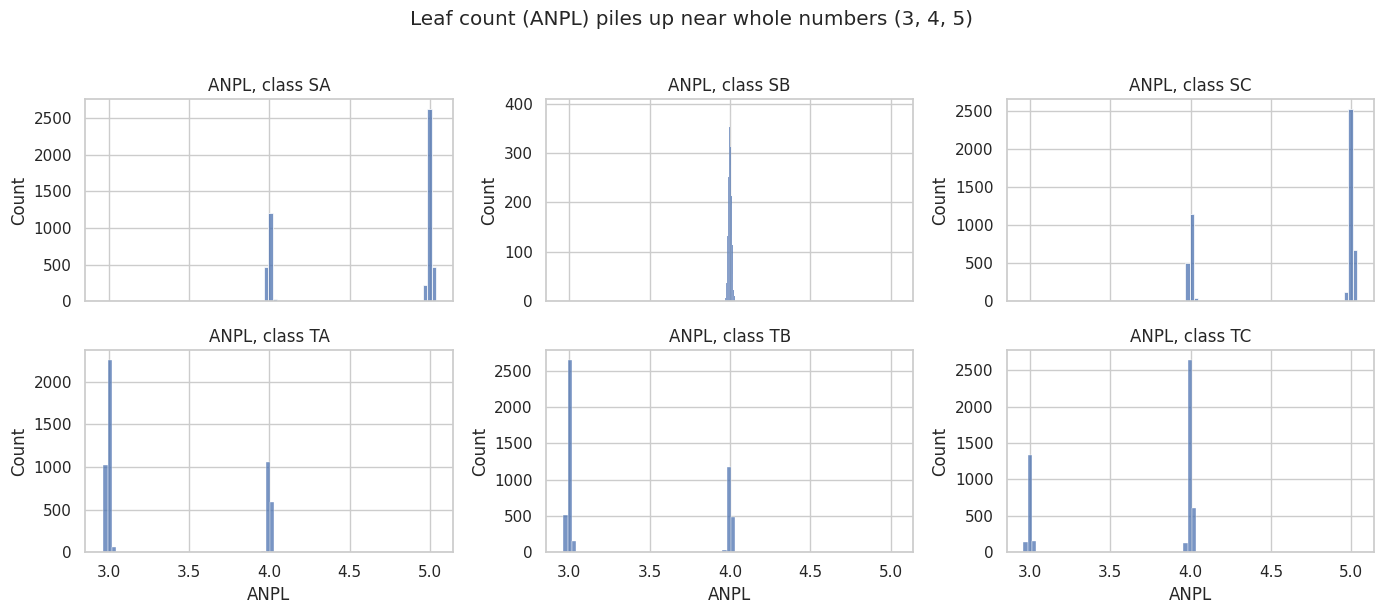

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, (cls, g) in zip(axes.ravel(), df.groupby("Class")):
    sns.histplot(g["ANPL"], bins=40, ax=ax)
    ax.set_title(f"ANPL, class {cls}")
fig.suptitle("Leaf count (ANPL) piles up near whole numbers (3, 4, 5)", y=1.02)
plt.tight_layout(); save(fig, "01_anpl_discrete_clusters"); plt.show()

- **ANPL (leaf count)** clusters tightly around whole numbers (about 3, 4 and 5 leaves) with small noise added, and class **SB has an almost constant ANPL** (CV ≈ 0.2%).
- Classes **SA and SC share identical ANPL distributions** (same mean and spread).
- Perfect classification from a single trait (section 9.1) is another sign of generated data.

I therefore describe the data as **likely simulated or augmented**. The source does not state this outright, so this is an inference.

### 4.3 The 30,000 rows are really 18 clusters
Each row belongs to one of 6 classes and one of 3 replicates, giving **18 class-replicate combinations ("cells")**. How much of each trait's variance is explained just by knowing the cell?

In [12]:
def eta_squared(frame, factor, trait):
    grand = frame[trait].mean()
    ss_between = sum(len(g) * (g[trait].mean() - grand) ** 2 for _, g in frame.groupby(factor))
    return ss_between / ((frame[trait] - grand) ** 2).sum()

df["Cell"] = df["Class"] + "_" + df["Replicate"]
cell_eta = pd.Series({t: eta_squared(df, "Cell", t) for t in TRAITS})
print(f"Number of cells: {df['Cell'].nunique()}  (rows per cell: {df['Cell'].value_counts().min()} to {df['Cell'].value_counts().max()})")
print(f"Variance explained by Class x Replicate cell: min {cell_eta.min():.3f}, mean {cell_eta.mean():.3f}, max {cell_eta.max():.3f}")
cell_eta.round(3)

Number of cells: 18  (rows per cell: 1625 to 1706)
Variance explained by Class x Replicate cell: min 0.996, mean 0.999, max 1.000


ACHP     1.000
PHR      1.000
AWWGV    0.998
ALAP     1.000
ANPL     1.000
ARD      1.000
ADWR     1.000
PDMVG    1.000
ARL      1.000
AWWR     1.000
ADWV     0.996
PDMRG    1.000
dtype: float64

Knowing the cell explains **99.6–100%** of the variance of every trait. Within a cell, rows differ only by tiny noise. So the dataset behaves like **18 distinct measurements, each repeated about 1,670 times with small jitter**.

Two consequences shape the rest of the analysis:
1. **Row-level p-values are inflated (pseudoreplication).** Rows inside a cell are near-copies, not independent plants, so tests on 30,000 rows overstate the evidence. Inference is done on the 18 cell means instead (section 6.1).
2. **Random cross-validation leaks.** A random split puts near-copies of every test row into the training set, so a model only has to recognise a cluster. Section 9 uses replicate-level validation to avoid this.

## 5. Exploratory data analysis

### 5.1 Distributions

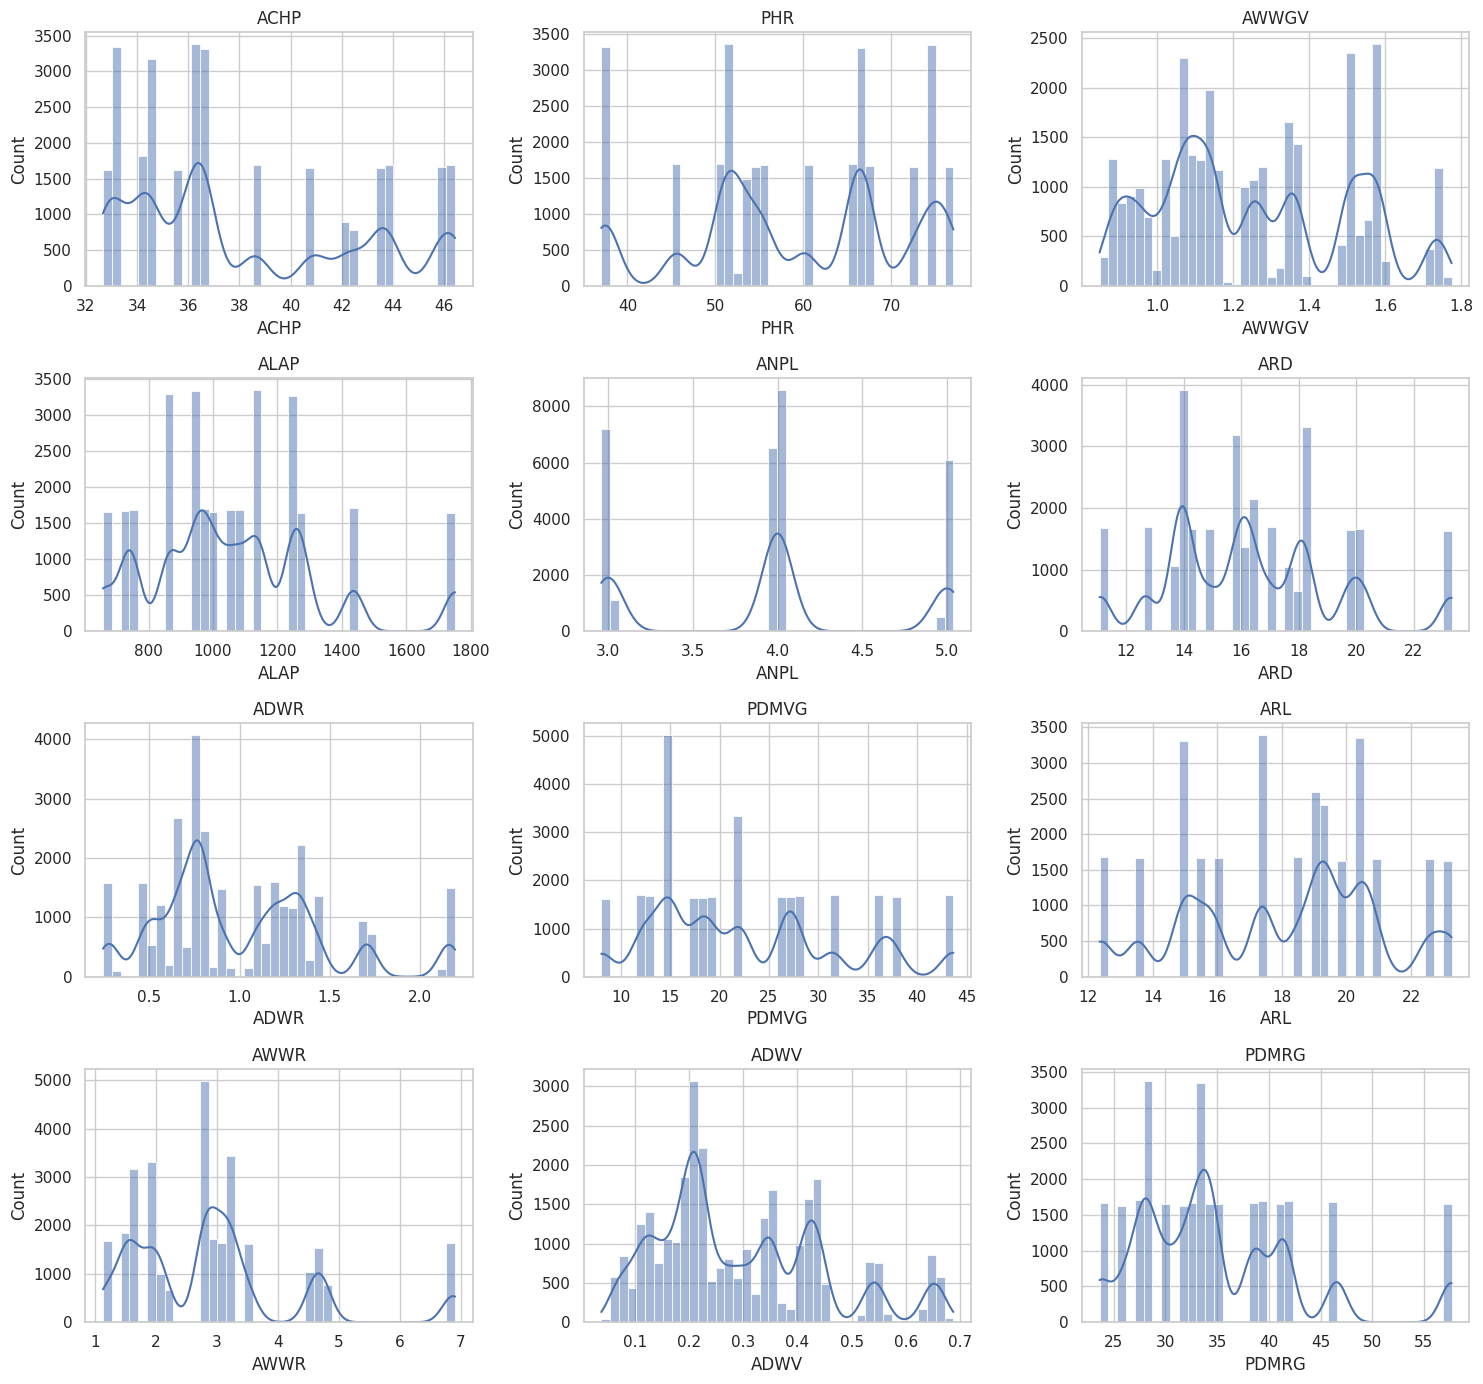

In [13]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, t in zip(axes.ravel(), TRAITS):
    sns.histplot(df[t], kde=True, ax=ax, bins=40)
    ax.set_title(t)
plt.tight_layout(); save(fig, "02_distributions"); plt.show()

Most traits are multi-modal, which is expected because they mix six distinct classes. This is why pooled means (and a pooled normality test) are not very informative here.

A note on normality: the original analysis used Shapiro-Wilk on all 30,000 rows. With samples this large the test rejects normality for trivial deviations, so it is not informative. I use skewness (table above) and visual checks, and choose rank-based tests that do not assume normality.

### 5.2 Traits by class

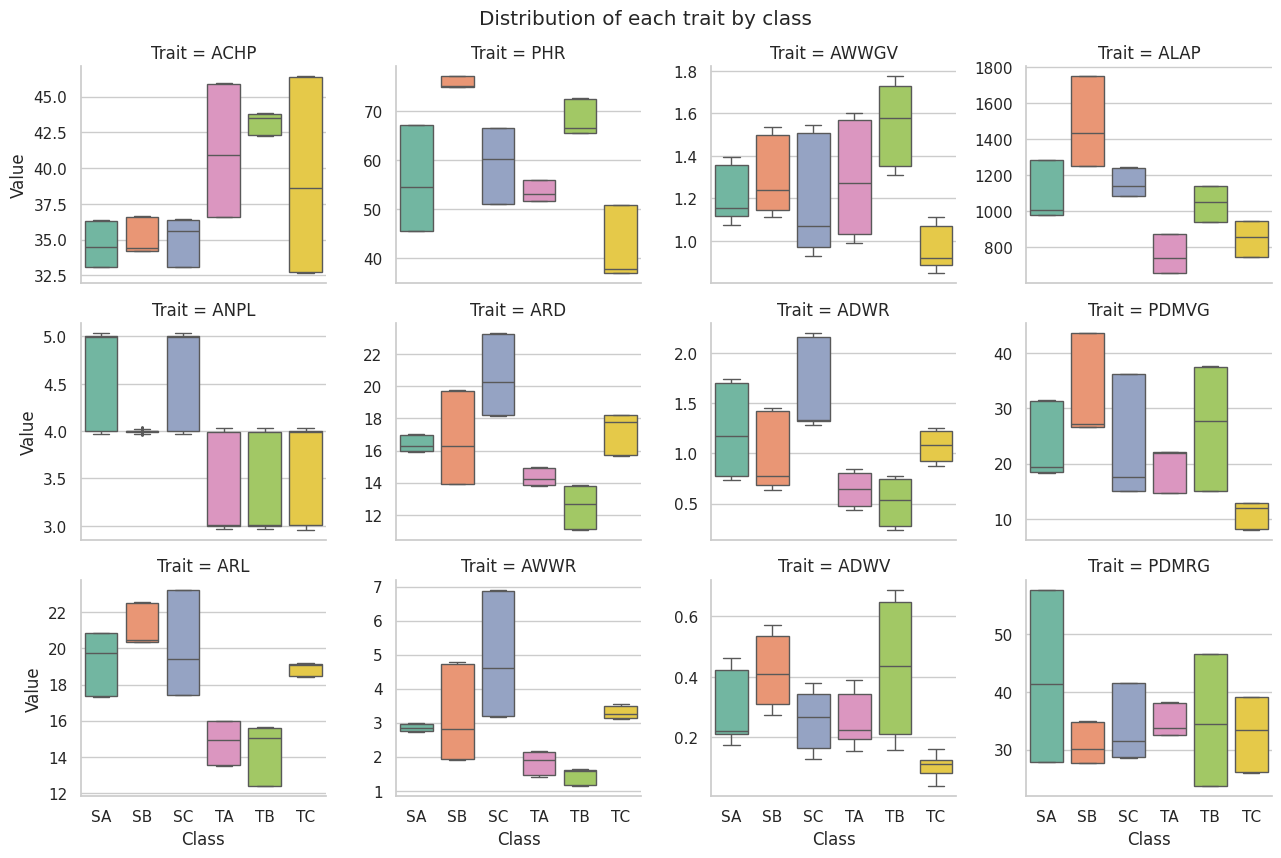

In [14]:
long = df.melt(id_vars=["Class"], value_vars=TRAITS, var_name="Trait", value_name="Value")
order = sorted(df["Class"].unique())
g = sns.catplot(data=long, x="Class", y="Value", col="Trait", col_wrap=4, kind="box",
                order=order, sharey=False, height=2.8, aspect=1.15, fliersize=1, palette="Set2")
g.fig.suptitle("Distribution of each trait by class", y=1.02)
save(g.fig, "03_boxplots_by_class"); plt.show()

### 5.3 Class profiles (z-scored class means)

The original notebook used a radar chart on min-max scaled means, which stretches tiny differences to fill 0–1. A heatmap of **z-scores of class means** shows the same profile idea without that distortion.

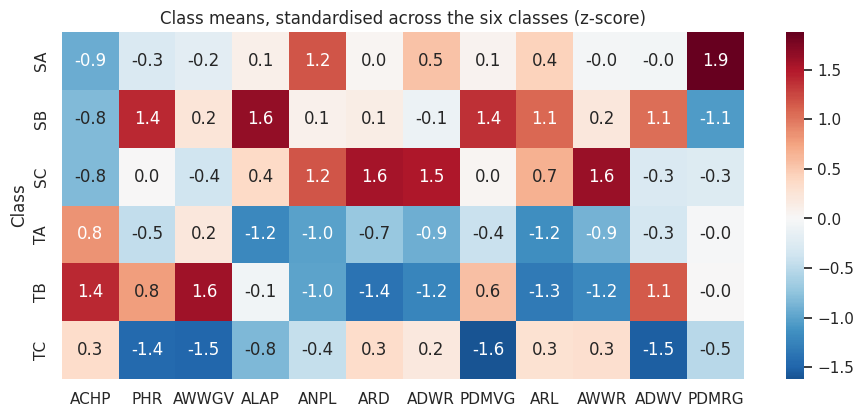

In [15]:
means = df.groupby("Class")[TRAITS].mean()
z = (means - means.mean()) / means.std()
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Class means, standardised across the six classes (z-score)")
save(fig, "04_class_profile_heatmap"); plt.show()

### 5.4 Correlations between traits

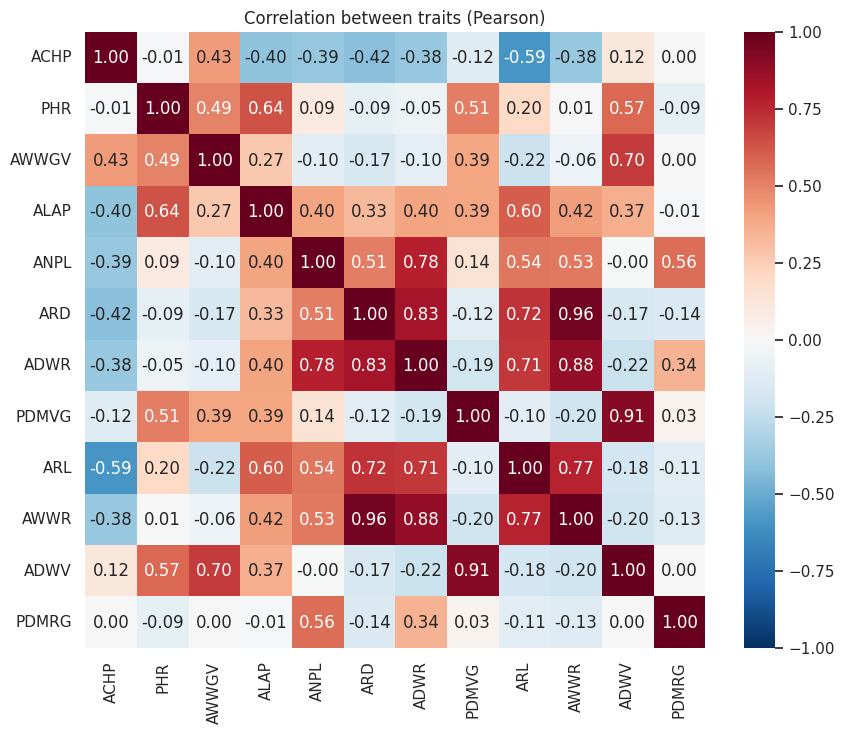

Pairs with |r| > 0.85: [('ARD', 'AWWR', np.float64(0.96)), ('ADWR', 'AWWR', np.float64(0.88)), ('PDMVG', 'ADWV', np.float64(0.91))]


In [16]:
corr = df[TRAITS].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between traits (Pearson)")
save(fig, "05_correlation_heatmap"); plt.show()

strong = [(a, b, round(corr.loc[a, b], 2)) for a, b in combinations(TRAITS, 2) if abs(corr.loc[a, b]) > 0.85]
print("Pairs with |r| > 0.85:", strong)

Three pairs are very strongly correlated (ARD–AWWR, PDMVG–ADWV and ADWR–AWWR). That is biologically plausible (thicker roots weigh more) but matters later: **correlated predictors share credit**, so feature-importance scores must be read with care.

## 6. Main question: do the two greenhouse types differ?
Because of section 4.3, I look at this in two steps:
1. **Descriptive (all 30,000 rows):** how big is the difference for each trait? (means, % difference, Cohen's d)
2. **Inferential (18 cell means):** is the difference statistically supported when the unit of analysis is the class-replicate cell, 9 for S and 9 for T?

Rough guide for Cohen's d: 0.2 small, 0.5 medium, 0.8 large.

In [17]:
def cohens_d(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

rows = []
for t in TRAITS:
    s, tr = df.loc[df.Greenhouse == "S", t], df.loc[df.Greenhouse == "T", t]
    rows.append({"Trait": t, "Mean S": s.mean(), "Mean T": tr.mean(),
                 "S vs T (%)": 100 * (s.mean() / tr.mean() - 1), "Cohen's d": cohens_d(s, tr)})
gh = pd.DataFrame(rows).set_index("Trait").sort_values("Cohen's d", key=abs, ascending=False)
gh.round({"Mean S": 2, "Mean T": 2, "S vs T (%)": 1, "Cohen's d": 2})

,Mean S,Mean T,S vs T (%),Cohen's d
Trait,,,,
ACHP,34.91,41.21,-15.3,-2.01
ANPL,4.44,3.45,28.8,2.00
ARL,20.13,16.01,25.7,1.97
ALAP,1242.06,885.22,40.3,1.88
ADWR,1.25,0.75,67.9,1.34
ARD,17.87,14.70,21.6,1.32
AWWR,3.62,2.19,65.5,1.24
PDMVG,26.24,19.11,37.4,0.80
PHR,63.48,54.56,16.3,0.80


### 6.1 Inference at the cell level (9 S cells vs 9 T cells)
Welch's t-test and the Mann-Whitney U test on the 18 cell means, with **Holm correction** across the 12 traits.

In [18]:
cells = df.groupby(["Class", "Replicate", "Greenhouse"])[TRAITS].mean().reset_index()
rows = []
for t in TRAITS:
    s, tr = cells.loc[cells.Greenhouse == "S", t], cells.loc[cells.Greenhouse == "T", t]
    rows.append({"Trait": t, "Mean S": s.mean(), "Mean T": tr.mean(),
                 "S vs T (%)": 100 * (s.mean() / tr.mean() - 1), "Cohen's d": cohens_d(s, tr),
                 "p (Welch t)": stats.ttest_ind(s, tr, equal_var=False)[1],
                 "p (Mann-Whitney)": stats.mannwhitneyu(s, tr)[1]})
cell_test = pd.DataFrame(rows).set_index("Trait")
cell_test["p (Holm-adjusted)"] = multipletests(cell_test["p (Welch t)"], method="holm")[1]
cell_test["Significant"] = cell_test["p (Holm-adjusted)"] < 0.05
cell_test = cell_test.sort_values("Cohen's d", key=abs, ascending=False)
cell_test.round({"Mean S": 2, "Mean T": 2, "S vs T (%)": 1, "Cohen's d": 2,
                 "p (Welch t)": 4, "p (Mann-Whitney)": 4, "p (Holm-adjusted)": 4})

,Mean S,Mean T,S vs T (%),Cohen's d,p (Welch t),p (Mann-Whitney),p (Holm-adjusted),Significant
Trait,,,,,,,,
ANPL,4.44,3.44,29.0,1.90,0.0010,0.0134,0.0118,True
ACHP,34.91,41.19,-15.2,-1.88,0.0028,0.0062,0.0254,True
ARL,20.15,16.02,25.8,1.87,0.0012,0.0027,0.0132,True
ALAP,1243.03,885.03,40.4,1.78,0.0021,0.0027,0.0213,True
ADWR,1.26,0.75,68.7,1.27,0.0178,0.0217,0.1426,False
ARD,17.88,14.71,21.6,1.24,0.0188,0.0171,0.1426,False
AWWR,3.63,2.19,65.8,1.17,0.0279,0.0521,0.1677,False
PHR,63.54,54.55,16.5,0.76,0.1260,0.1333,0.6299,False
PDMVG,26.15,19.11,36.9,0.75,0.1321,0.1333,0.6299,False


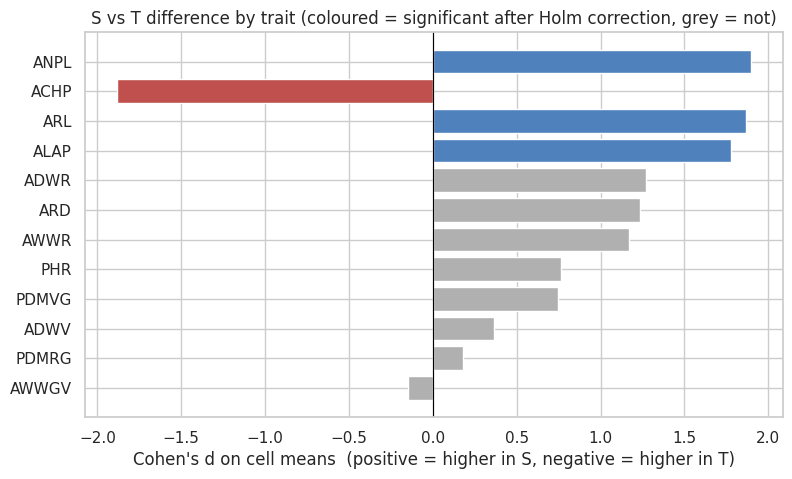

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
d_vals = cell_test["Cohen's d"][::-1]
sig = cell_test["Significant"][::-1]
colors = [("#4f81bd" if d > 0 else "#c0504d") if s_ else "#b0b0b0" for d, s_ in zip(d_vals, sig)]
ax.barh(d_vals.index, d_vals, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Cohen's d on cell means  (positive = higher in S, negative = higher in T)")
ax.set_title("S vs T difference by trait (coloured = significant after Holm correction, grey = not)")
save(fig, "06_greenhouse_effect_sizes"); plt.show()

**Reading the result.** Four traits show a difference that survives a statistically honest test:
- **ACHP (chlorophyll): higher in T** (about 15%).
- **ANPL (leaf count), ARL (root length) and ALAP (leaf area): higher in S** (about 29%, 26% and 40%).

Root weight, root diameter and root dry weight are also much larger in S (d above 1.1), but with only 9 groups per greenhouse they do not pass the correction, so I describe them as **suggestive, not established**. PDMRG and AWWGV show no meaningful difference.

## 7. What drives each trait: greenhouse, group or replicate?
Eta-squared (η²) is the share of a trait's total variance explained by a factor (0 = none, 1 = all). I compute it separately for `Greenhouse`, `Group`, `Replicate` and the combined `Class`.

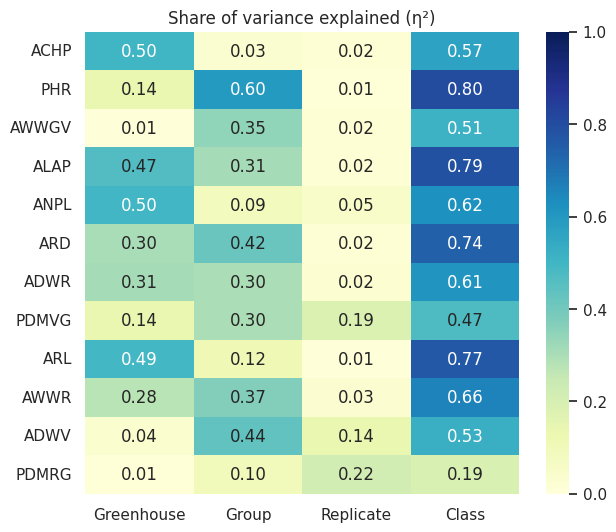

In [20]:
def eta_squared(frame, factor, trait):
    grand = frame[trait].mean()
    ss_between = sum(len(g) * (g[trait].mean() - grand) ** 2 for _, g in frame.groupby(factor))
    return ss_between / ((frame[trait] - grand) ** 2).sum()

eta = pd.DataFrame({f: {t: eta_squared(df, f, t) for t in TRAITS}
                    for f in ["Greenhouse", "Group", "Replicate", "Class"]})
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(eta, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax)
ax.set_title("Share of variance explained (η²)")
save(fig, "07_eta_squared"); plt.show()

- **Greenhouse** matters most for ACHP, ANPL, ARL and ALAP (η² ≈ 0.47–0.50).
- **Group (A/B/C)** matters most for PHR (≈ 0.60), ADWV and ARD.
- **Replicate** explains little for most traits (≤ 0.05), but more for PDMVG (≈ 0.19), PDMRG (≈ 0.22) and ADWV (≈ 0.14). Replicates are *not* interchangeable draws: they shift some traits, and (section 9) that shift matters for generalisation.

### 7.1 Which classes differ from which? (post-hoc tests)
A Kruskal-Wallis test only says "some class differs". **Dunn's test with Holm correction** compares every pair of the six classes. I summarise across all traits and show one trait (PHR) in detail. *These tests use all rows, so with the pseudoreplication from section 4.3 they are descriptive only; read them as "the clusters are clearly apart", not as evidence strength.*

In [21]:
kw = pd.Series({t: stats.kruskal(*[g[t].values for _, g in df.groupby("Class")])[1] for t in TRAITS})
print("Kruskal-Wallis p-values are all < 1e-5:", bool((kw < 1e-5).all()))

n_pairs = len(list(combinations(df["Class"].unique(), 2)))
sig_pairs = {}
for t in TRAITS:
    d = sp.posthoc_dunn(df, val_col=t, group_col="Class", p_adjust="holm")
    sig_pairs[t] = int(((d.values < 0.05).sum() - len(d)) / 2)
print(f"\nSignificant class pairs (out of {n_pairs}) per trait:")
print(pd.Series(sig_pairs).to_string())
print(f"\nTotal: {sum(sig_pairs.values())} of {n_pairs * len(TRAITS)} comparisons")

Kruskal-Wallis p-values are all < 1e-5: True



Significant class pairs (out of 15) per trait:
ACHP     12
PHR      12
AWWGV    12
ALAP     12
ANPL     10
ARD      12
ADWR     12
PDMVG    12
ARL      12
AWWR     12
ADWV     11
PDMRG    12

Total: 141 of 180 comparisons


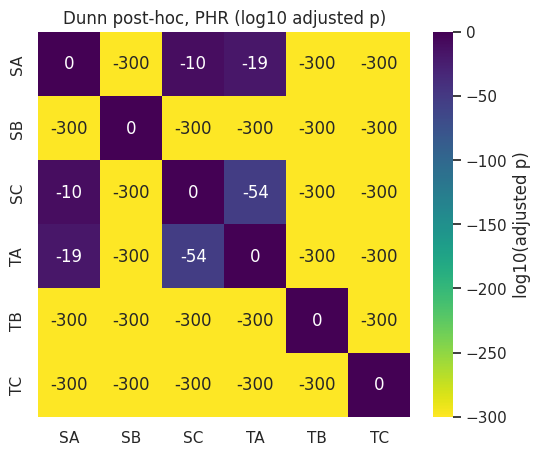

In [22]:
dunn_phr = sp.posthoc_dunn(df, val_col="PHR", group_col="Class", p_adjust="holm")
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(np.log10(dunn_phr.clip(lower=1e-300)), annot=True, fmt=".0f", cmap="viridis_r", ax=ax,
            cbar_kws={"label": "log10(adjusted p)"})
ax.set_title("Dunn post-hoc, PHR (log10 adjusted p)")
save(fig, "08_dunn_phr"); plt.show()

Most pairs are significant for most traits. Since rows are near-copies (section 4.3), the informative question is *how big* the differences are (sections 6–7), not whether they are non-zero.

## 8. Structure in the data: PCA
Do the six classes form natural clusters if we ignore the labels?

Explained variance ratio, first 4 PCs: [0.382 0.264 0.127 0.096] | cumulative first 2: 0.647


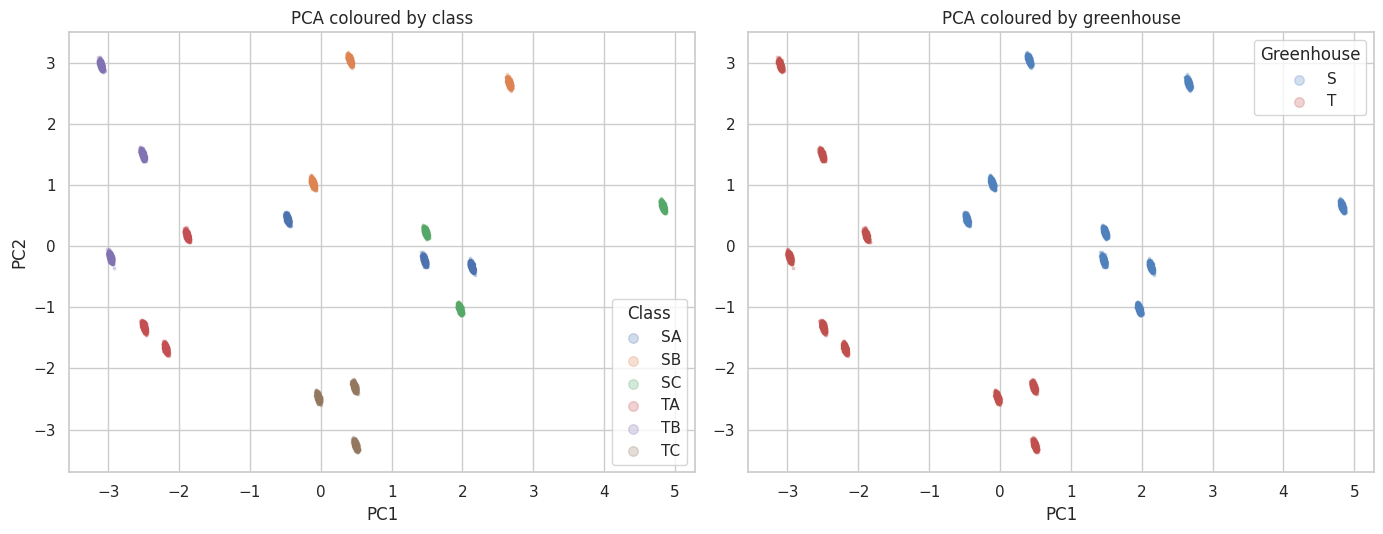

In [23]:
Xz = StandardScaler().fit_transform(df[TRAITS])
pca = PCA().fit(Xz)
pcs = pca.transform(Xz)
print("Explained variance ratio, first 4 PCs:", pca.explained_variance_ratio_[:4].round(3),
      "| cumulative first 2:", pca.explained_variance_ratio_[:2].sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for cls in order:
    m = (df["Class"] == cls).values
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=3, alpha=0.25, label=cls)
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].legend(markerscale=4, title="Class"); axes[0].set_title("PCA coloured by class")
for gh_, c_ in zip(["S", "T"], ["#4f81bd", "#c0504d"]):
    m = (df["Greenhouse"] == gh_).values
    axes[1].scatter(pcs[m, 0], pcs[m, 1], s=3, alpha=0.25, color=c_, label=gh_)
axes[1].set_xlabel("PC1"); axes[1].legend(markerscale=4, title="Greenhouse")
axes[1].set_title("PCA coloured by greenhouse")
plt.tight_layout(); save(fig, "09_pca"); plt.show()

The plot does **not** show six clouds. It shows **18 tiny, tight clusters**: each class splits into three clusters, one per replicate, and the clusters sit far apart from each other. This is the same structure quantified in section 4.3, and real plant measurements almost never form 18 point-like clusters.

T clusters (red, right panel) sit mostly on the left of PC1 and S clusters mostly on the right, with a few T clusters near PC1 ≈ 0.5, so the greenhouse split is strong but not perfectly clean in these two components. The first two components carry about 65% of the variance.

## 9. Modelling: how well can the class be predicted, and can we trust it?
The original analysis reported accuracy of 1.0 for logistic regression, random forest and gradient boosting. That result needs scrutiny before it can be presented as a strength.

What I changed compared with the original notebook:
- Only the 12 trait columns are predictors (`Replicate` was previously label-encoded and fed to the models, which wrongly implies an order R1 < R2 < R3 and adds no real information).
- Logistic regression is wrapped with a scaler.
- Results use **stratified 5-fold cross-validation**, not one train/test split.
- A harder, more honest test is added: **leave-one-replicate-out**. This matters because of section 4.3: with ~1,670 near-copies per cluster, a random split puts a near-copy of every test row into the training set.

In [24]:
X = df[TRAITS]
y = df["Class"]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

models = {
    "Logistic Regression (scaled)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Gradient Boosting (hist)": HistGradientBoostingClassifier(random_state=SEED),
}
cv_scores = {name: cross_val_score(m, X, y, cv=skf) for name, m in models.items()}
pd.DataFrame({n: {"Mean accuracy": s.mean(), "Std": s.std()} for n, s in cv_scores.items()}).T.round(4)

,Mean accuracy,Std
Logistic Regression (scaled),1.0,0.0
Random Forest,1.0,0.0
Gradient Boosting (hist),1.0,0.0


All three models are essentially perfect. Before celebrating, I check how little information is needed.

### 9.1 How few traits are enough?

In [25]:
tree = DecisionTreeClassifier(max_depth=6, random_state=SEED)
single = pd.Series({t: cross_val_score(tree, X[[t]], y, cv=skf).mean() for t in TRAITS}).sort_values(ascending=False)
pair_scores = sorted(((cross_val_score(tree, X[[a, b]], y, cv=skf).mean(), a, b)
                      for a, b in combinations(TRAITS, 2)), reverse=True)

print("Accuracy using ONE trait (shallow decision tree, 5-fold CV):")
print(single.round(3).to_string())
n_perfect = sum(s >= 0.999 for s, _, _ in pair_scores)
print(f"\nTrait pairs reaching ~100%: {n_perfect} of {len(pair_scores)}")
print("Examples:", [(a, b, round(s, 3)) for s, a, b in pair_scores[:4]])

Accuracy using ONE trait (shallow decision tree, 5-fold CV):
ALAP     1.000
PDMRG    1.000
ARL      1.000
AWWR     0.982
PHR      0.945
ADWR     0.922
PDMVG    0.898
ACHP     0.886
ARD      0.870
AWWGV    0.782
ADWV     0.750
ANPL     0.382

Trait pairs reaching ~100%: 37 of 66
Examples: [('PHR', 'PDMRG', np.float64(1.0)), ('PHR', 'AWWR', np.float64(1.0)), ('PHR', 'ARL', np.float64(1.0)), ('PHR', 'ALAP', np.float64(1.0))]


Even **a single trait (ALAP, ARL or PDMRG) reaches ~100%**, and 37 of the 66 trait pairs do too. Real biological measurements almost never separate six groups this cleanly from one variable. A depth-6 tree can carve many narrow intervals, so it can effectively *memorise* tight clusters of values, which is what the next test checks.

In [26]:
loro_single = {t: cross_val_score(DecisionTreeClassifier(max_depth=6, random_state=SEED), X[[t]], y,
                                  cv=LeaveOneGroupOut(), groups=df["Replicate"]) for t in ["ALAP", "ARL", "PDMRG", "PHR"]}
pd.DataFrame({
    "Random 5-fold CV": {t: single[t] for t in loro_single},
    "Held out R1": {t: s[0] for t, s in loro_single.items()},
    "Held out R2": {t: s[1] for t, s in loro_single.items()},
    "Held out R3": {t: s[2] for t, s in loro_single.items()},
}).round(2)

,Random 5-fold CV,Held out R1,Held out R2,Held out R3
ALAP,1.00,0.17,0.50,0.34
ARL,1.00,0.50,0.16,0.33
PDMRG,1.00,0.00,0.00,0.17
PHR,0.95,0.50,0.33,0.16


The same single-trait trees that score ~100% under random cross-validation score only **0–50%** when a replicate is held out (PDMRG is at 0% for two of the three). The classes occupy tight, replicate-specific clusters of values; a random split lets the model see every cluster during training, a replicate split does not.

### 9.2 Leave-one-replicate-out validation
The replicates R1, R2 and R3 are separate batches. If a model has learned something real about the classes, it should still work when trained on two replicates and tested on the third. Random k-fold splits mix all replicates together and cannot detect this problem.

I run it two ways: the **six-class** task and the simpler **S vs T** task.

In [27]:
logo = LeaveOneGroupOut()
groups = df["Replicate"]
rf_ = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
lr_ = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))

rows = []
for task, target in [("Six classes", df["Class"]), ("S vs T", df["Greenhouse"])]:
    for name, model in [("Random Forest", rf_), ("Logistic Regression", lr_)]:
        s = cross_val_score(model, X, target, cv=logo, groups=groups)
        rows.append({"Task": task, "Model": name, "Held out R1": s[0], "Held out R2": s[1],
                     "Held out R3": s[2], "Mean": s.mean()})
loro = pd.DataFrame(rows).set_index(["Task", "Model"]).round(3)
loro

Held out R1  Held out R2  Held out R3   Mean
Task        Model                                                            
Six classes Random Forest              0.665        0.499        0.335  0.500
            Logistic Regression        0.666        0.534        0.493  0.564
S vs T      Random Forest              1.000        1.000        1.000  1.000
            Logistic Regression        0.836        1.000        0.830  0.889

**This is the most important result of the modelling section.**
- The **S vs T** distinction holds up when a whole replicate is hidden (random forest ≈ 100%), so the greenhouse effect is real *within this dataset*.
- The **six-class** accuracy collapses to roughly one-third to two-thirds, which is far below the ≈100% from random cross-validation. The A/B/C separation depends on replicate-specific patterns (see the PHR means by replicate below), not on stable class features.

In [28]:
df.groupby(["Class", "Replicate"])["PHR"].mean().unstack().round(1)

Replicate,R1,R2,R3
Class,,,
SA,54.6,67.1,45.6
SB,75.0,77.0,74.9
SC,51.1,60.2,66.5
TA,53.0,51.7,55.9
TB,72.5,65.5,66.6
TC,37.9,37.1,50.8


Where do the six-class errors go? A confusion matrix for the hardest case (train on R1+R2, test on R3):

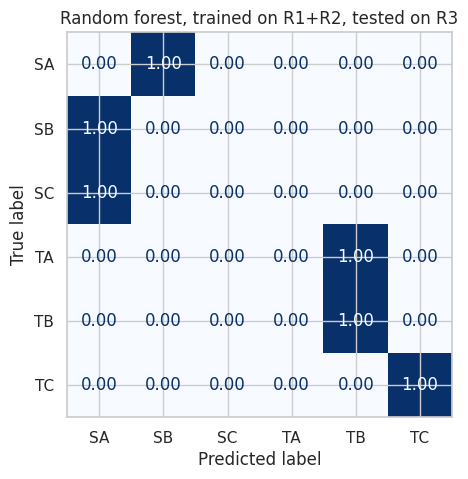

In [29]:
train, test = df["Replicate"] != "R3", df["Replicate"] == "R3"
rf_fit = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X[train], y[train])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(rf_fit, X[test], y[test], normalize="true",
                                      values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Random forest, trained on R1+R2, tested on R3")
save(fig, "10_confusion_matrix_heldout_R3"); plt.show()

In [30]:
for rep_ in ["R1", "R2", "R3"]:
    tr_, te_ = df["Replicate"] != rep_, df["Replicate"] == rep_
    pred = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X[tr_], y[tr_]).predict(X[te_])
    wrong = pred != y[te_].values
    same_gh = np.mean([p[0] == a[0] for p, a in zip(pred[wrong], y[te_].values[wrong])])
    print(f"Held out {rep_}: {wrong.sum()} errors, {same_gh:.1%} of them stay within the same greenhouse")

Held out R1: 3369 errors, 99.0% of them stay within the same greenhouse


Held out R2: 4989 errors, 100.0% of them stay within the same greenhouse


Held out R3: 6643 errors, 100.0% of them stay within the same greenhouse


Almost every error is a confusion **within** a greenhouse (S-classes mixed up with other S-classes, T with T), and almost none cross between S and T. This matches the S-vs-T result above.

### 9.3 Which traits does the model rely on?

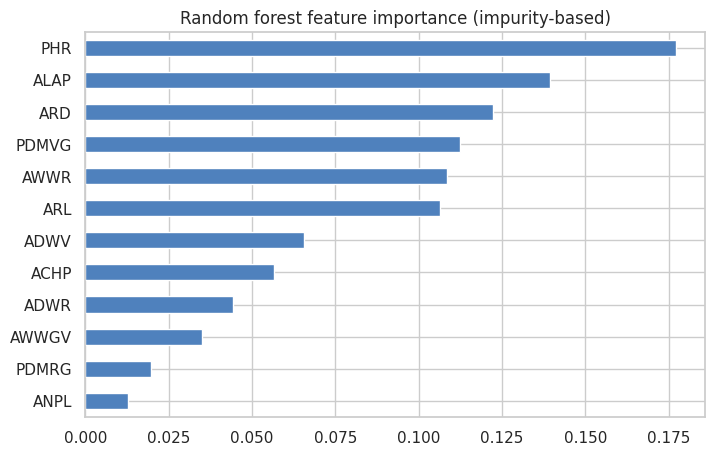

,Impurity importance,Permutation importance (accuracy drop)
PHR,0.177,0.188
ALAP,0.139,0.000
ARD,0.122,0.000
PDMVG,0.112,0.000
AWWR,0.109,0.000
ARL,0.106,0.000
ADWV,0.066,0.000
ACHP,0.057,0.000
ADWR,0.044,0.000
AWWGV,0.035,0.000


In [31]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
rf_imp = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
perm = permutation_importance(rf_imp, Xte, yte, n_repeats=5, random_state=SEED, n_jobs=-1)

imp = pd.DataFrame({"Impurity importance": rf_imp.feature_importances_,
                    "Permutation importance (accuracy drop)": perm.importances_mean},
                   index=TRAITS).sort_values("Impurity importance", ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
imp["Impurity importance"][::-1].plot.barh(ax=ax, color="#4f81bd")
ax.set_title("Random forest feature importance (impurity-based)")
save(fig, "11_feature_importance"); plt.show()
imp.round(3)

PHR is the most important trait under both measures. Permutation importance is near zero for every other trait because the traits are redundant: if one is shuffled, the others still carry the signal. This is a limitation of permutation importance with correlated, highly separable features, so I read the importance ranking as "PHR leads, the rest overlap".

## 10. Conclusions

**Answer to the main question.** Within this dataset, the two greenhouse types differ. Tested properly on the 18 group means, four traits differ significantly after correction: chlorophyll is higher in T, while leaf count, root length and leaf area are higher in S (effect sizes d ≈ 1.8–1.9). Root weight and diameter also lean strongly toward S but are not firmly established with 9 groups per greenhouse. The S-vs-T pattern is stable when a whole replicate is held out, which gives some confidence that it is a property of the data and not a splitting artefact.

**What the models really tell us.** Near-perfect accuracy from standard cross-validation is not evidence of a powerful model. It reflects how separable the classes are, probably because the values were generated or augmented. The leave-one-replicate-out test shows the six-class result does not generalise across batches.

**What I would tell a non-technical reader.** The data shows a clear, consistent difference between the two greenhouse types. It does not support claims about predicting the finer A/B/C groups, and it should not be treated as real field evidence.

## 11. Limitations
- **Likely simulated or augmented data** (section 4.2). Statistical results describe this dataset, not real plants.
- **Undocumented labels.** S/T = smart/traditional is my inference. A/B/C and `Replicate` are not defined by the source.
- **No units, dates, or plant IDs.** Rows cannot be tied to individual plants or time, so growth over time cannot be studied and the independence assumption of the tests cannot be verified.
- **Effective sample size is 18, not 30,000.** Rows within a class-replicate cell are near-copies (section 4.3), so inference uses 9 vs 9 group means. That limits statistical power and is why some large effects are not significant.
- **Redundant predictors** make feature-importance rankings unreliable.

## 12. Possible next steps
- Obtain the thesis or contact the dataset author to confirm the label definitions and whether the data was augmented.
- Repeat the analysis on a genuinely measured greenhouse dataset to see whether the same S-vs-T pattern appears.
- Build a small interactive app (for example Streamlit) to explore trait differences by class.

---
*Data: Advanced IoT Agriculture 2024, Kaggle (wisam1985), Tikrit University, Iraq. Please cite the original source when reusing the data.*

## Appendix: plain-language summary chart
The chart below is the one used in the accompanying report and README. It uses the 18 cell means from section 6.1 (the significant traits only) and the PCA coordinates from section 8.

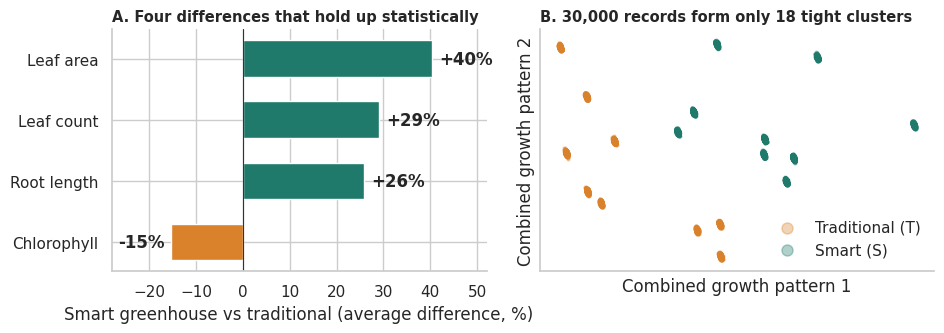

In [32]:
TEAL, ORANGE = "#1F7A6B", "#D9822B"
labels = {"ALAP": "Leaf area", "ANPL": "Leaf count", "ARL": "Root length", "ACHP": "Chlorophyll"}
pct = cell_test.loc[list(labels), "S vs T (%)"].sort_values()

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.5), gridspec_kw={"width_ratios": [1, 1.05]})
bars = ax[0].barh([labels[k] for k in pct.index], pct.values,
                  color=[TEAL if v > 0 else ORANGE for v in pct.values], height=0.6)
for b, v in zip(bars, pct.values):
    ax[0].text(v + (1.5 if v > 0 else -1.5), b.get_y() + b.get_height() / 2, f"{v:+.0f}%",
               va="center", ha="left" if v > 0 else "right", fontweight="bold")
ax[0].axvline(0, color="#333", lw=0.8); ax[0].set_xlim(-28, 52)
ax[0].set_xlabel("Smart greenhouse vs traditional (average difference, %)")
ax[0].set_title("A. Four differences that hold up statistically", fontsize=10.5, loc="left", fontweight="bold")

for g, c, l in [("T", ORANGE, "Traditional (T)"), ("S", TEAL, "Smart (S)")]:
    m = (df["Greenhouse"] == g).values
    ax[1].scatter(pcs[m, 0], pcs[m, 1], s=4, alpha=0.35, color=c, label=l)
ax[1].legend(markerscale=4, frameon=False, loc="lower right")
ax[1].set_xticks([]); ax[1].set_yticks([])
ax[1].set_xlabel("Combined growth pattern 1"); ax[1].set_ylabel("Combined growth pattern 2")
ax[1].set_title("B. 30,000 records form only 18 tight clusters", fontsize=10.5, loc="left", fontweight="bold")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); save(fig, "12_summary_chart"); plt.show()